# GR00T N1 and N1.5, step by step 🦾
### System 2 reasons, System 1 denoises: one network for many robot bodies, learning from video that has no actions

**Models:** `GR00TPolicy` with `GR00TConfig.n1()` / `GR00TConfig.n1_5()` (`src/Halo_VLA/open_vlas/groot.py`) · **latent actions:** `open_vlas/latent_actions.py` ·
**papers:** NVIDIA, *GR00T N1: An Open Foundation Model for Generalist Humanoid Robots*, 2025 ([arXiv:2503.14734](https://arxiv.org/abs/2503.14734)); R. Zheng et al., *FLARE: Robot Learning with Implicit
World Modeling*, 2025 ([arXiv:2505.15659](https://arxiv.org/abs/2505.15659)); N1.5 release notes ([research.nvidia.com/labs/gear/gr00t-n1_5](https://research.nvidia.com/labs/gear/gr00t-n1_5/)).

**GR00T N1** is a *dual-system* foundation model for humanoids:

* **System 2** (slow): a pretrained VLM (**Eagle-2**) reads the camera images and the instruction. Its hidden states from a **middle layer** (the 12th of 24), not the last one, are the conditioning;
* **System 1** (fast): a **diffusion transformer (DiT)** with *alternating cross-attention and self-attention blocks* denoises an action chunk, conditioned on the VLM features and the robot's state;
* **embodiment-specific MLPs** in front of and behind the DiT (one set per robot body) let the *same* network train on arms, humanoids, even *latent actions* from video;
* a **data pyramid**: real-robot teleoperation at the peak, synthetic data (simulation, video-generated "neural trajectories") in the middle, human video and web data at the base.

**GR00T N1.5** keeps the architecture and changes four things: the **VLM is fully frozen**, the VLM→DiT adapter gets **layer normalisation**, a **FLARE** loss (weight 0.2) aligns a few DiT "future tokens" with the
embedding of the future frame, and more synthetic data. This notebook builds the architecture (Steps 1-5), then each of the paper's central ideas in turn:

| step | idea | question we answer with an experiment |
|---|---|---|
| 5 | one DiT for several embodiments | can one network drive a point robot, a joint-space robot and a robot with a gripper? |
| 6 | middle-layer VLM features | is the middle of the VLM better than its end? |
| 7 | latent actions from video | what does a VQ-VAE inverse-dynamics model learn from frames alone? |
| 8 | cross-embodiment pre-training | how much does pre-training on *other* robots help a new robot with few demonstrations? |
| 9 | N1 → N1.5 | frozen VLM, LayerNorm adapter, FLARE: what does each add? |

| | published GR00T N1 (2B) | this notebook |
|---|---|---|
| System 2 | Eagle-2 (SmolLM2 + SigLIP-2), 1.34B, layer 12 of 24, 64 tokens/frame | toy VLM, 6 layers, layer 3, 16 tokens/frame |
| System 1 | DiT, adaLN, alternating cross/self-attention; chunk H = 16; K = 4 Euler steps | DiT (width 64, 4 blocks), H = 16, K = 4 |
| embodiments | GR-1 humanoid, OpenX arms, AgiBot, sim humanoids, latent-action "LAPA" | `point2d`, `joint2d`, `gripper3d`, `lapa` (latent) |
| pre-training | ≈50,000 H100 GPU-hours | 3000 steps on a laptop |

> **How to read the results.** One seed, 96 unseen scenes per number; small gaps are noise, large effects are real. Where the toy disagrees with the paper we say so. Total runtime is about 45 minutes on a laptop CPU.

## Step 0: Setup, and four robot bodies in one world

The same point world as in the other notebooks, but now the *robot* varies. The task is always `"go to <colour>"`; what differs is what the policy **sees (state)** and **says (action)**:

| embodiment | state | action | what is different |
|---|---|---|---|
| `point2d` | `(x, y)` | 2: end-effector displacement | the baseline |
| `joint2d` | `(x, y)` | 2: **joint-space** command (end-effector motion = `J · a` for a fixed 2×2 matrix `J`) | same body, different action space |
| `gripper3d` | `(x, y, g)` | 3: displacement + **gripper command** (must close within 0.15 of the target; success needs the gripper closed) | an extra degree of freedom |
| `lapa` | none | 4: a **latent action** learned from video | not a robot (Step 7) |

GR00T handles this by **zero-padding** every state / action to the largest size inside a batch and routing each sample through the MLPs of *its own* embodiment (Step 2).

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import vla_kit
vla_kit.setup_paths()
from vla_kit import plots, diagrams as dg

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, ForwardFlow, ToyVLM, VLMConfig, VLMPretrainer,
                       make_embodied_scenarios, make_reach_demos)
from open_vlas.data import collate
from open_vlas.embodiments import MAX_ACTION_DIM, MAX_STATE_DIM, embodied_arrays
from open_vlas.groot import (AdaLayerNorm, CategorySpecificLinear, GR00TConfig, GR00TPolicy)
from open_vlas.latent_actions import LatentActionModel, frame_pair_sampler, train_latent_action_model
from pi_family import PiTrainer
from pi_family.toy import DemoGenerator, PointWorld

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld()
gen = DemoGenerator(world)
print("torch", torch.__version__)

torch 2.13.0


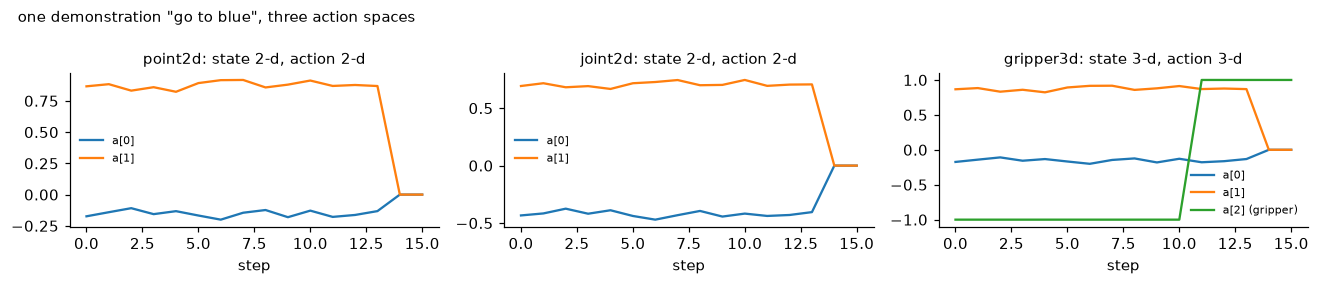

In [2]:
# the same demonstration, expressed in each embodiment's action space
ep = make_reach_demos(gen, 1, np.random.default_rng(4))[0]
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6), facecolor="white")
for ax, name in zip(axes, ("point2d", "joint2d", "gripper3d")):
    states, actions = embodied_arrays(ep, EMBODIMENTS[name])
    for d in range(actions.shape[1]):
        ax.plot(actions[: ep.active_steps + 2, d], label=f"a[{d}]" + (" (gripper)" if name == "gripper3d" and d == 2 else ""))
    ax.set_title(f"{name}: state {EMBODIMENTS[name].state_dim}-d, action {EMBODIMENTS[name].action_dim}-d", fontsize=9.5)
    ax.set_xlabel("step"); ax.legend(fontsize=7.5, frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.suptitle(f'one demonstration "{ep.task}", three action spaces', x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

### 🖼️ Diagram: GR00T N1, and the data it learns from

Blue = System 2 (the VLM), red = System 1 (the DiT and the embodiment-specific encoders and decoder).

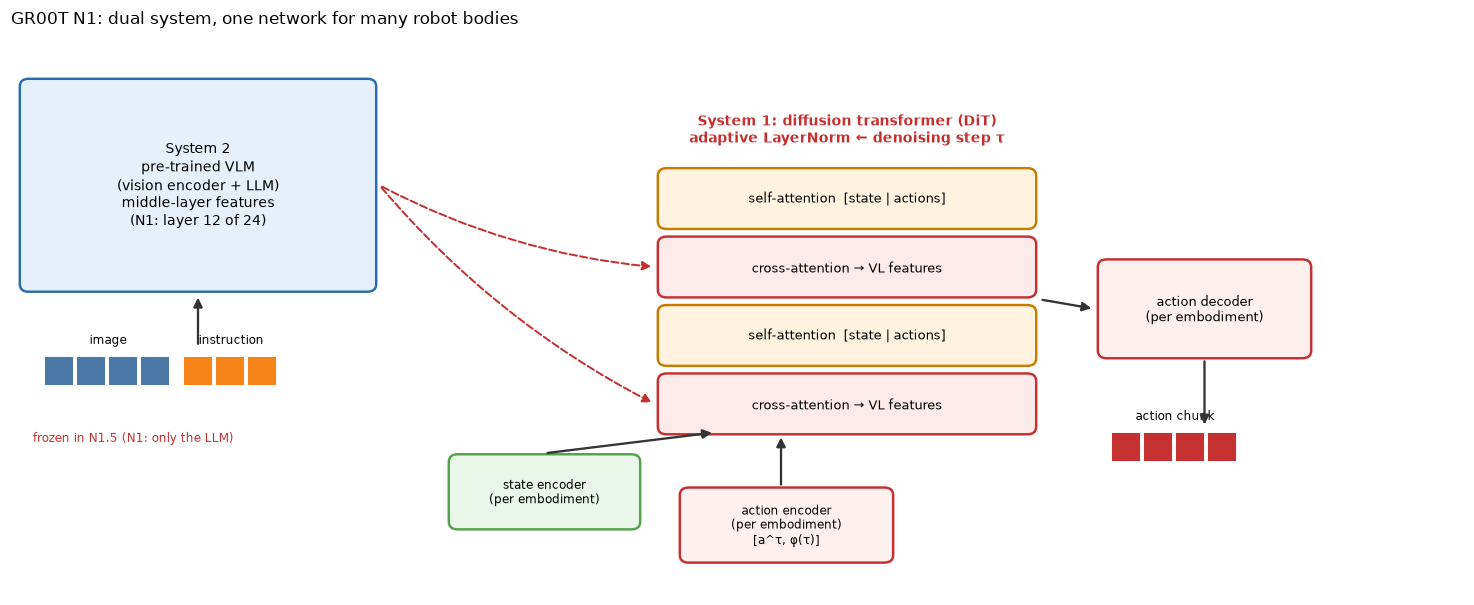

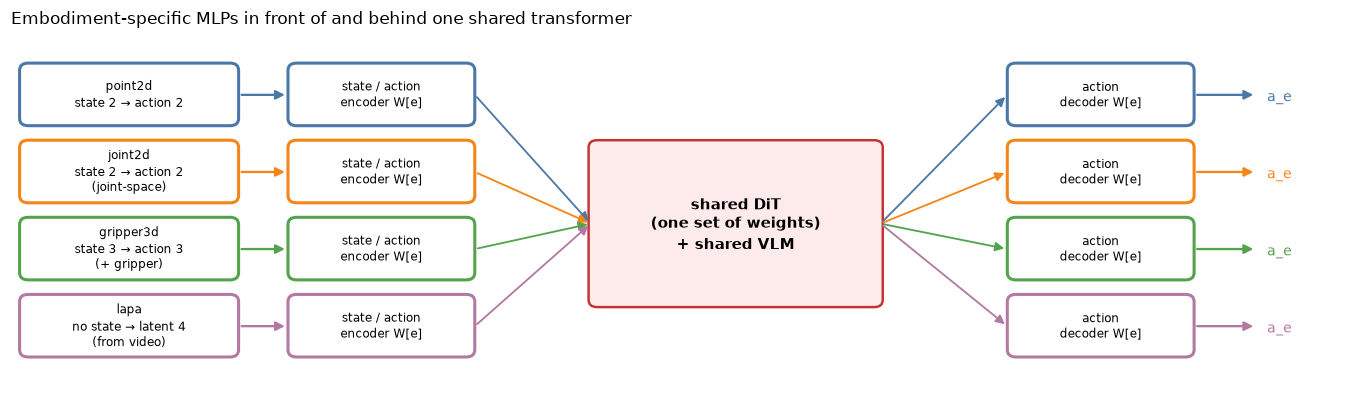

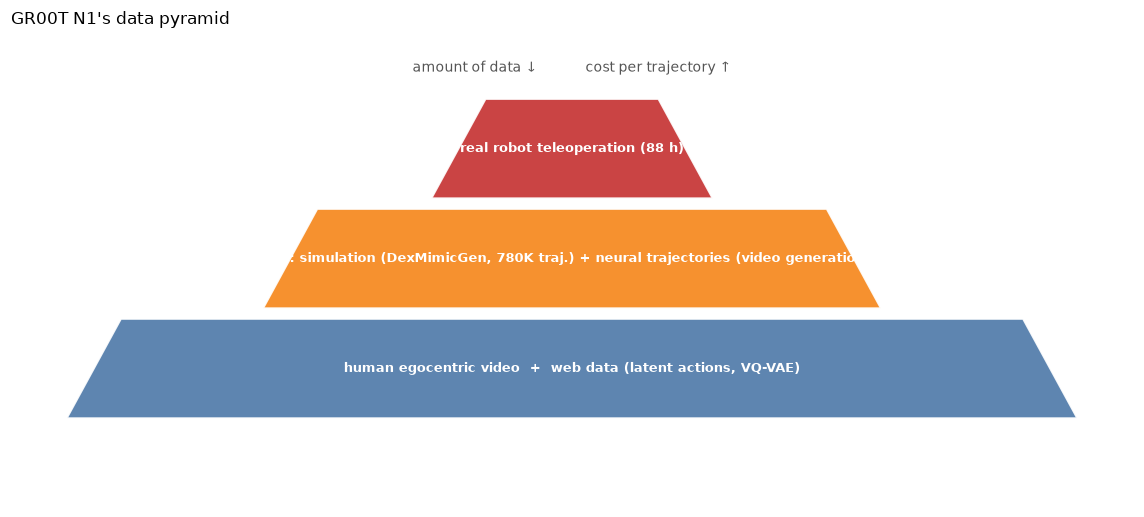

In [3]:
dg.fig_groot_architecture()
dg.fig_embodiment_routing()
dg.fig_data_pyramid()

## Step 1: System 2: a pretrained VLM, read at a middle layer

GR00T N1 passes the images and the instruction to **Eagle-2**, an off-the-shelf VLM, in its chat format, and extracts the LLM's hidden states `φ_t` of shape *(batch, sequence, hidden)*.
The paper's design note: *"using middle-layer instead of final-layer LLM embeddings resulted in both faster inference speed and higher downstream policy success rate"*; for GR00T-N1-2B they use
the **12th layer** of 24, and the layers above are not even run. During policy training the **language component is frozen**; the vision encoder is fine-tuned (N1), and in **N1.5 everything is frozen**.

Unlike SmolVLA, GR00T does **not** put the robot state in the VLM's sequence: the state goes to the DiT (Step 3). So the VLM input is just `[image tokens | prompt tokens]`.

As in the SmolVLA notebook, our toy VLM gets a head start from visual question answering (stage 0), the stand-in for Eagle-2's web-scale pre-training.

VLM pre-training step   500  loss 0.626  token accuracy 0.78


VLM pre-training step  1000  loss 0.108  token accuracy 0.94


VLM pre-training step  1500  loss 0.146  token accuracy 0.91
VLM pre-training: 36 s, answer-token accuracy 0.93
N1 reads the features after layer 3 of 6 (paper: 12 of 24); the remaining layers are discarded


VLM input: (6, 21, 64) = (B, 16 image + words, width) → features φ_t: (6, 21, 64)


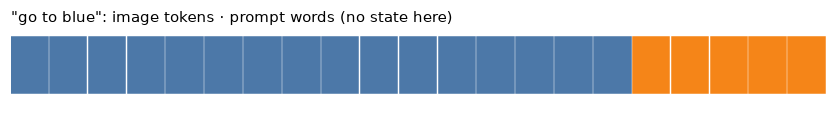

In [4]:
vlm = ToyVLM(VLMConfig())
pre = VLMPretrainer(vlm, world)
pre.fit(1500, log_every=500)
print(f"VLM pre-training: {pre.history.seconds:.0f} s, answer-token accuracy {np.mean(pre.history.accuracy[-50:]):.2f}")
cfg = GR00TConfig.n1()
print(f"N1 reads the features after layer {cfg.vlm_layer} of {vlm.num_layers} (paper: 12 of 24); the remaining layers are discarded")

demos = make_reach_demos(gen, 3000, np.random.default_rng(0))
mix = EmbodiedMixture([EmbodiedSource(world, demos, EMBODIMENTS[n]) for n in ("point2d", "joint2d", "gripper3d")])
batch = mix.sample(6, np.random.default_rng(1))
v = copy.deepcopy(vlm).truncate(cfg.vlm_layer)
with torch.no_grad():
    inp = v.build_inputs(batch.images, batch.task)
    phi = v.forward_layers(inp)[-1]
print("VLM input:", tuple(inp.embeds.shape), "= (B, 16 image + words, width) → features φ_t:", tuple(phi.shape))
plots.plot_token_layout(inp, vlm.vocab, example=0, title=f'"{batch.task[0]}": image tokens · prompt words (no state here)')

## Step 2: Embodiment-specific MLPs

Different robots have different state and action dimensions (GR-1 humanoid: dozens of joints plus two dexterous hands; a single arm: 7-8). GR00T N1 *"uses an MLP per embodiment to project
[state and action] to a shared embedding dimension as input to the DiT"*, and a per-embodiment **action decoder** MLP on the way out. The building block is `CategorySpecificLinear`: a stack of
weight matrices `W[e]`, and sample `b` of a batch is multiplied by `W[embodiment[b]]`.

Everything in a batch is **zero-padded** to the largest dimensions (`MAX_STATE_DIM = 3`, `MAX_ACTION_DIM = 4`), and a **mask** says which action dimensions are real so that padded dimensions carry no
noise, no loss and no output.

embodiment ids in the batch: [1, 0, 0, 1, 1, 1] (0 = point2d, 1 = joint2d, 2 = gripper3d)
routing each sample through its own matrix == explicit loop: True

state (zero-padded to 3):
 [[0.84 0.79 0.  ]
 [0.25 0.68 0.  ]
 [0.68 0.75 0.  ]
 [0.59 0.69 0.  ]
 [0.34 0.43 0.  ]
 [0.57 0.74 0.  ]]


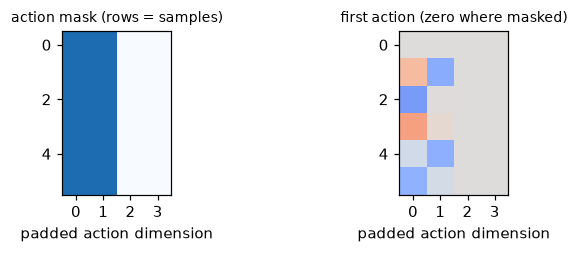

In [5]:
layer = CategorySpecificLinear(4, 3, 5)
x, cat = torch.randn(6, 3), batch.embodiment
manual = torch.stack([x[i] @ layer.weight[cat[i]] + layer.bias[cat[i]] for i in range(6)])
print("embodiment ids in the batch:", cat.tolist(), "(0 = point2d, 1 = joint2d, 2 = gripper3d)")
print("routing each sample through its own matrix == explicit loop:", torch.allclose(layer(x, cat), manual, atol=1e-6))

print("\nstate (zero-padded to 3):\n", batch.state.numpy().round(2))
fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.4))
axes[0].imshow(batch.action_mask.numpy(), cmap="Blues", vmin=0, vmax=1.3); axes[0].set_title("action mask (rows = samples)", fontsize=9)
axes[0].set_xticks(range(MAX_ACTION_DIM)); axes[0].set_xlabel("padded action dimension")
axes[1].imshow(batch.actions[:, 0].numpy(), cmap="coolwarm", vmin=-1.5, vmax=1.5); axes[1].set_title("first action (zero where masked)", fontsize=9)
axes[1].set_xticks(range(MAX_ACTION_DIM)); axes[1].set_xlabel("padded action dimension")
plt.tight_layout(); plt.show()

## Step 3: Flow matching, the GR00T way, and the encoders

**The convention.** GR00T (and FLARE) write the noised chunk as

$$A^\tau = \tau A + (1-\tau)\,\varepsilon,\qquad \text{target } \varepsilon\text{-direction: } V_\theta(\varphi_t, A^\tau, q_t) \approx A-\varepsilon,\qquad \tau \sim \text{Beta}\!\Big(\tfrac{s-\tau}{s};\,1.5,\,1\Big),\; s = 0.999$$

so **τ = 0 is pure noise and τ = 1 is data**, and sampling integrates *forward* from τ = 0 with `K` Euler steps, `K = 4` in all of the paper's experiments. This is the mirror image of the π0 / SmolVLA code (where
τ = 1 is noise); the two are the same method under `τ ↔ 1 − τ`. `ForwardFlow` implements it. The Beta distribution puts most training time on the noisy end (small τ), like π0's.

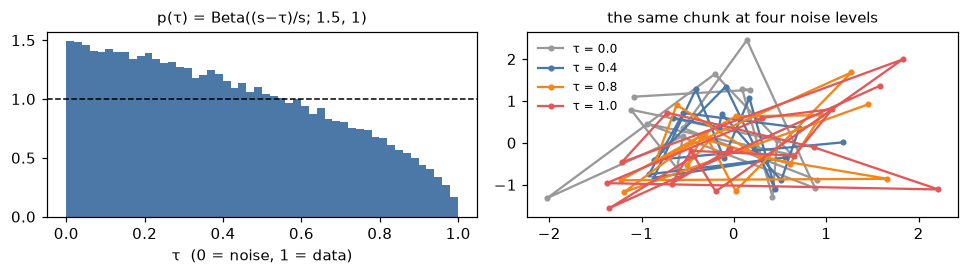

integrating the true velocity from noise with 4 Euler steps recovers the data: True


In [6]:
flow = ForwardFlow()
t = flow.sample_time(100_000, generator=torch.Generator().manual_seed(0))
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
axes[0].hist(t.numpy(), bins=50, density=True, color="#4c78a8"); axes[0].axhline(1, color="k", ls="--", lw=1)
axes[0].set_xlabel("τ  (0 = noise, 1 = data)"); axes[0].set_title("p(τ) = Beta((s−τ)/s; 1.5, 1)", fontsize=10)
a, eps = torch.randn(1, 16, 2), torch.randn(1, 16, 2)
for tau, col in ((0.0, "#999999"), (0.4, "#4c78a8"), (0.8, "#f58518"), (1.0, "#e45756")):
    x = flow.interpolate(a, eps, torch.tensor([tau]))[0]
    axes[1].plot(x[:, 0], x[:, 1], "o-", ms=3, color=col, label=f"τ = {tau}")
axes[1].legend(fontsize=8, frameon=False); axes[1].set_title("the same chunk at four noise levels", fontsize=10)
plt.tight_layout(); plt.show()
print("integrating the true velocity from noise with 4 Euler steps recovers the data:", torch.allclose(flow.integrate(lambda x, t: flow.target_velocity(a, eps), eps, 4), a, atol=1e-5))

**The state and action encoders.** The robot state `q_t` becomes **one token** through its embodiment's state encoder (an MLP). Each *noised action* is encoded together with the denoising step (as in π0):
`W3 · swish(W2 · [W1·a^τ , φ(τ)])`, again with per-embodiment weights. The DiT's input sequence is therefore `[state token | H action tokens]` (plus M "future tokens" in N1.5, Step 9).

In [7]:
torch.manual_seed(0)
model = GR00TPolicy(vlm, GR00TConfig.n1())
dev = model.action_position.device
emb, state = batch.embodiment, batch.state
noisy = flow.interpolate(batch.actions, torch.randn_like(batch.actions) * batch.action_mask[:, None], torch.full((6,), 0.3))
with torch.no_grad():
    s_tok = model.state_encoder(state, emb)
    a_tok = model.action_encoder(noisy, torch.full((6,), 0.3), emb)
print("state token:", tuple(s_tok.shape), "= (B, DiT width)    action tokens:", tuple(a_tok.shape), "= (B, H, DiT width)")
print({k: f"{v:,}" for k, v in model.parameter_counts().items()})

state token: (6, 64) = (B, DiT width)    action tokens: (6, 16, 64) = (B, H, DiT width)
{'total': '422,992', 'trainable': '286,608', 'vlm': '162,112', 'dit': '173,568', 'embodiment_specific': '86,288'}


## Step 4: System 1: the diffusion transformer

The DiT `V_θ` is a stack of blocks that **alternate cross-attention and self-attention** (as in Flamingo / VIMA):

* **self-attention** runs over the sequence `[state token, noised action tokens]`: the actions see the state and each other (bidirectionally, unlike SmolVLA's causal mask);
* **cross-attention** lets those tokens read the **VLM features** `φ_t` (their `k`/`v` projections map the VLM's width to the DiT's);
* the denoising step τ enters through **adaptive LayerNorm**: each block's input normalisation has a scale and shift *predicted from τ's embedding* (the DiT recipe from image diffusion);
* after the last block an **embodiment-specific action decoder** MLP maps the `H` action tokens to actions.

Every `AdaLayerNorm` is **zero-initialised**, so at the start of training each block sees a plain LayerNorm and the freshly initialised DiT is harmless.

['cross', 'self', 'cross', 'self'] ← alternating, starting with cross-attention (reading the VLM before mixing actions)
AdaLayerNorm at initialisation == plain LayerNorm: True
DiT output (padded action velocity): (6, 16, 4) | attention maps per block: [('cross', (6, 4, 17, 21)), ('self', (6, 4, 17, 17)), ('cross', (6, 4, 17, 21)), ('self', (6, 4, 17, 17))]


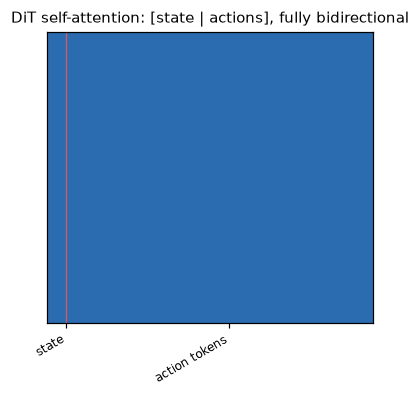

In [8]:
print([b.kind for b in model.blocks], "← alternating, starting with cross-attention (reading the VLM before mixing actions)")
x, temb = torch.randn(2, 5, 64), torch.randn(2, 64)
print("AdaLayerNorm at initialisation == plain LayerNorm:", torch.allclose(AdaLayerNorm(64)(x, temb), torch.nn.functional.layer_norm(x, (64,)), atol=1e-5))
with torch.no_grad():
    ctx = model.encode(batch)
    tau = torch.full((6,), 0.3)
    out, weights = model.velocity(ctx, noisy, tau, state, emb, return_weights=True)
print("DiT output (padded action velocity):", tuple(out.shape), "| attention maps per block:", [(k, tuple(w.shape)) for k, w in weights])
tokens = ["state"] + [f"a{i}" for i in range(16)]
plots.plot_mask(torch.ones(17, 17, dtype=torch.bool), [("state", 0, 1), ("action tokens", 1, 17)], title="DiT self-attention: [state | actions], fully bidirectional", size=3.4)

## Step 5: One network, three robot bodies

We train **one** GR00T N1 on a mixture of `point2d`, `joint2d` and `gripper3d` demonstrations (3000 episodes each), with the usual recipe: flow-matching loss, per-embodiment MLPs, VLM language part frozen
and vision encoder trained, AdamW. Then we evaluate the same network on each body.

step   625  loss 0.0944  (flow 0.094)


step  1250  loss 0.0614  (flow 0.061)


step  1875  loss 0.0351  (flow 0.035)


step  2500  loss 0.0285  (flow 0.029)
trained in 102 s; trainable parameters 286,608 of 422,992


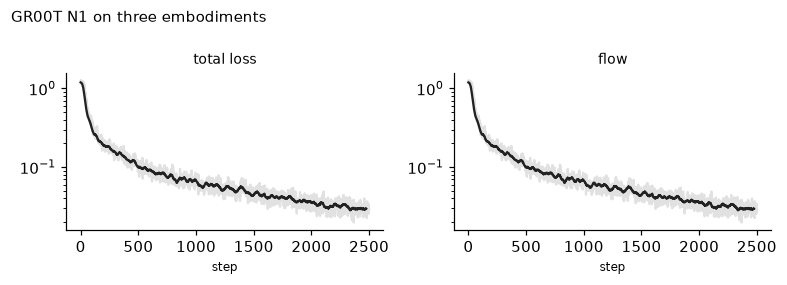

point2d    {'success': 0.99, 'steps': 12.4, 'path': 0.491, 'wrong_first': 0.01}
joint2d    {'success': 0.99, 'steps': 11.6, 'path': 0.493, 'wrong_first': 0.021}
gripper3d  {'success': 0.917, 'steps': 12.7, 'path': 0.499, 'wrong_first': 0.031}


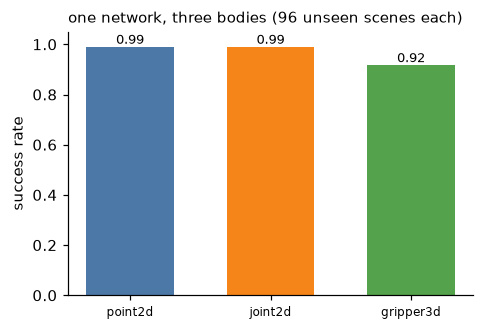

In [9]:
torch.manual_seed(0)
n1 = GR00TPolicy(vlm, GR00TConfig.n1())
hist = PiTrainer(n1, mix, batch_size=64, lr=2e-3, grad_clip=10.0).fit(2500, log_every=625)
print(f"trained in {hist.seconds:.0f} s; trainable parameters {n1.parameter_counts()['trainable']:,} of {n1.parameter_counts()['total']:,}")
plots.plot_loss(hist, keys=("flow",), title="GR00T N1 on three embodiments")
ev = EmbodiedEvaluator(world, 16, 8, 50)
results = {e: ev.run(lambda b: n1.sample_actions(b), make_embodied_scenarios(gen, e, 96, 123)) for e in ("point2d", "joint2d", "gripper3d")}
for e, r in results.items():
    print(f"{e:10s}", r.summary())
plots.bar_compare({e: r.success_rate for e, r in results.items()}, "success rate", "one network, three bodies (96 unseen scenes each)", ylim=(0, 1.05), colors=["#4c78a8", "#f58518", "#54a24b"])

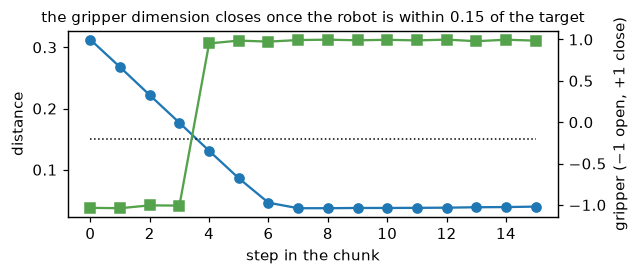

In [10]:
# the gripper dimension: the first chunk predicted for a gripper3d scene, against the distance to the target
scen = make_embodied_scenarios(gen, "gripper3d", 1, seed=21)
obs = ev.observe(scen, np.stack([s.scene.robot[None] for s in scen]).repeat(2, 1), np.full(1, -1.0), 0)
with torch.no_grad():
    chunk = n1.sample_actions(obs)[0].numpy()
target = scen[0].scene.objects[scen[0].target]
pos, d = [scen[0].scene.robot.copy()], []
for a in chunk:
    pos.append(world.step(pos[-1], a[:2], "ee")); d.append(np.linalg.norm(pos[-1] - target))
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(d, "o-", label="distance to the target"); ax.plot(0.15 * np.ones(16), "k:", lw=1)
ax2 = ax.twinx(); ax2.plot(chunk[:, 2], "s-", color="#54a24b", label="predicted gripper command")
ax.set_xlabel("step in the chunk"); ax.set_ylabel("distance"); ax2.set_ylabel("gripper (−1 open, +1 close)")
ax.set_title("the gripper dimension closes once the robot is within 0.15 of the target", fontsize=9.5)
plt.tight_layout(); plt.show()

### How many denoising steps? `K`

GR00T N1 found `K = 4` enough *"across all embodiments"*. Cheap to check on the trained model:

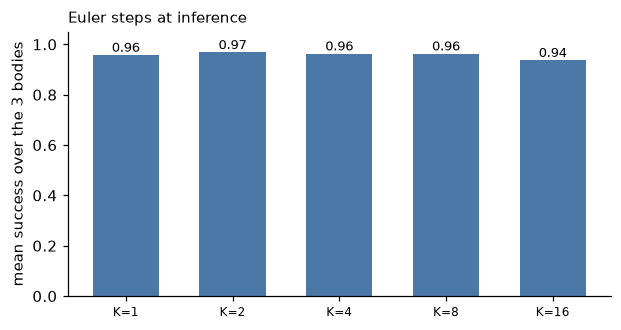

In [11]:
ks = {}
for K in (1, 2, 4, 8, 16):
    ks[f"K={K}"] = float(np.mean([ev.run(lambda b, K=K: n1.sample_actions(b, num_steps=K), make_embodied_scenarios(gen, e, 64, 7)).success_rate for e in ("point2d", "joint2d", "gripper3d")]))
plots.bar_compare(ks, "mean success over the 3 bodies", "Euler steps at inference", ylim=(0, 1.05))

## Step 6: Which VLM layer? Middle vs last

The paper's claim is that **middle-layer VLM features beat final-layer features**, in speed and in downstream success. We train the same GR00T three times, reading the VLM after layer 1, layer 3 (half, our default) and layer 6 (the last),
on the same mixture and for the same number of steps:

read the VLM after layer 1: mean success 0.22, final flow loss 0.109, VLM parameters 79,936


read the VLM after layer 3: mean success 0.95, final flow loss 0.030, VLM parameters 162,112


read the VLM after layer 6: mean success 0.90, final flow loss 0.036, VLM parameters 285,376


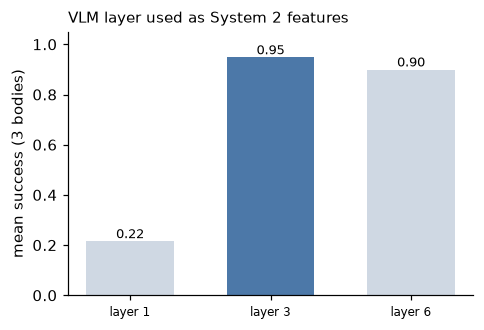

In [12]:
layer_results = {}
for layer in (1, 3, 6):
    if layer == 3:
        m, h = n1, hist
    else:
        torch.manual_seed(0)
        m = GR00TPolicy(vlm, GR00TConfig.n1(vlm_layer=layer))
        h = PiTrainer(m, mix, batch_size=64, lr=2e-3, grad_clip=10.0).fit(2500)
    rs = [ev.run(lambda b: m.sample_actions(b), make_embodied_scenarios(gen, e, 96, 123)).success_rate for e in ("point2d", "joint2d", "gripper3d")]
    layer_results[f"layer {layer}"] = dict(success=float(np.mean(rs)), flow=float(np.mean(h.series("flow")[-100:])), vlm_params=sum(p.numel() for p in m.vlm.parameters()))
    print(f"read the VLM after layer {layer}: mean success {np.mean(rs):.2f}, final flow loss {layer_results[f'layer {layer}']['flow']:.3f}, VLM parameters {layer_results[f'layer {layer}']['vlm_params']:,}", flush=True)
plots.bar_compare({k: v["success"] for k, v in layer_results.items()}, "mean success (3 bodies)", "VLM layer used as System 2 features", ylim=(0, 1.05), colors=["#cfd8e3", "#4c78a8", "#cfd8e3"])

**Reading this.** Reading only layer 1 fails (the features have no location information yet, as the SmolVLA probe showed), but **layer 3 (half the depth) is at least as good as layer 6 (the last)**, at 57 % of the VLM's
parameters and compute. The paper reports middle layers as both *faster* and *better* than the last one; we reproduce the *faster at no cost* half of that claim; whether it is also better is within the noise of one seed
here (there is little for the deeper layers of a toy this small to over-specialise on). It is a design knob worth testing, not a law.

## Step 7: Latent actions: learning from video with no action labels

Human egocentric video and generated "neural trajectories" have **no robot actions**. GR00T N1 turns them into training data with a **latent-action model**: a VQ-VAE over pairs of frames `(x_t, x_{t+H})`.
The encoder sees both frames and emits a small vector `z`; `z` is snapped to the nearest of a few **codebook** entries (the information bottleneck); the decoder sees only `x_t` and the code and must reconstruct
`x_{t+H}`. Because the future cannot be guessed from `x_t` alone, the code has to carry *what happened*. After training, the encoder is an **inverse-dynamics model**: the pre-quantisation embedding is used as the
"action" label for the flow-matching loss, as a pseudo-embodiment called **LAPA**. Training one VQ-VAE on all datasets together puts every embodiment's video in one shared latent space.

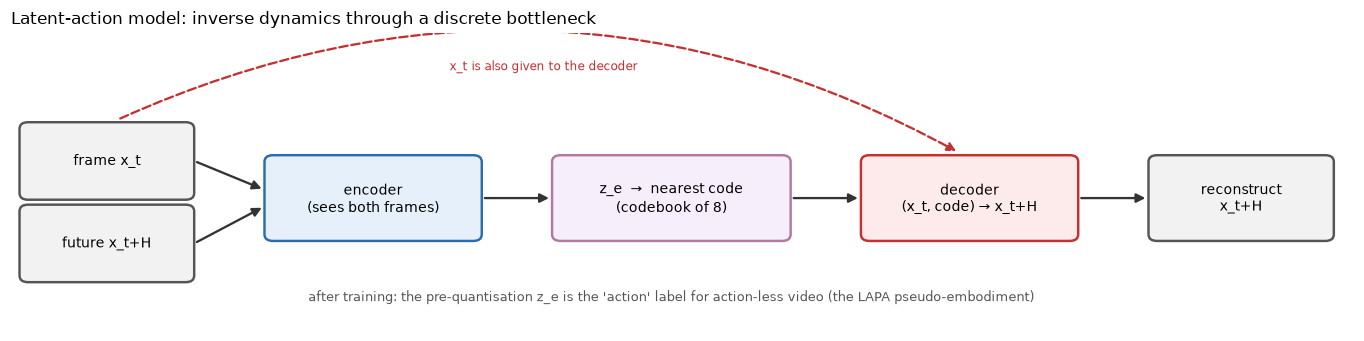

In [13]:
dg.fig_latent_action_model()

latent-action model step   500  recon 0.2204  codes used 4


latent-action model step  1000  recon 0.0501  codes used 5


latent-action model step  1500  recon 0.0242  codes used 6
trained in 116 s


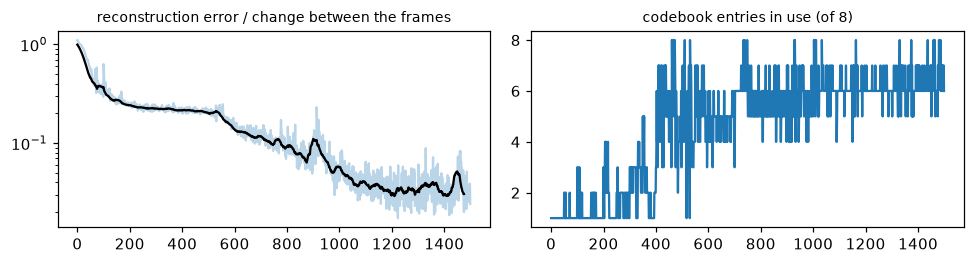

In [14]:
RG, ALL = ("red", "green"), ("red", "green", "blue")
video_demos = make_reach_demos(gen, 3000, np.random.default_rng(1), ALL)      # "human video": all three colours, we only ever use the frames
video_src = EmbodiedSource(world, video_demos, EMBODIMENTS["lapa"])
sampler = frame_pair_sampler(video_src, 16)
torch.manual_seed(0)
lam = LatentActionModel()
lhist = train_latent_action_model(lam, sampler, 1500, log_every=500)
print(f"trained in {lhist.seconds:.0f} s")
fig, axes = plt.subplots(1, 2, figsize=(9, 2.5))
axes[0].plot(lhist.recon, alpha=0.3); axes[0].plot(np.convolve(lhist.recon, np.ones(25) / 25, mode="valid"), color="k"); axes[0].set_yscale("log")
axes[0].set_title("reconstruction error / change between the frames", fontsize=9)
axes[1].plot(lhist.codes_used); axes[1].set_title("codebook entries in use (of 8)", fontsize=9)
plt.tight_layout(); plt.show()

**What did it learn?** Take pairs of frames the model never trained on. (i) How well does the decoder reconstruct the future from `(x_t, code)`, compared with *predicting no change* and with using a *wrong* (shuffled) code?
(ii) The counterfactual picture: the same current frame decoded with **every code** in the codebook shows the 8 different futures the latent vocabulary can express.

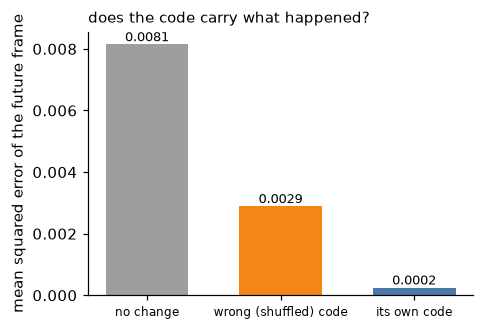

codes in use on held-out pairs: [164  11 232   0  98 162 104 229]


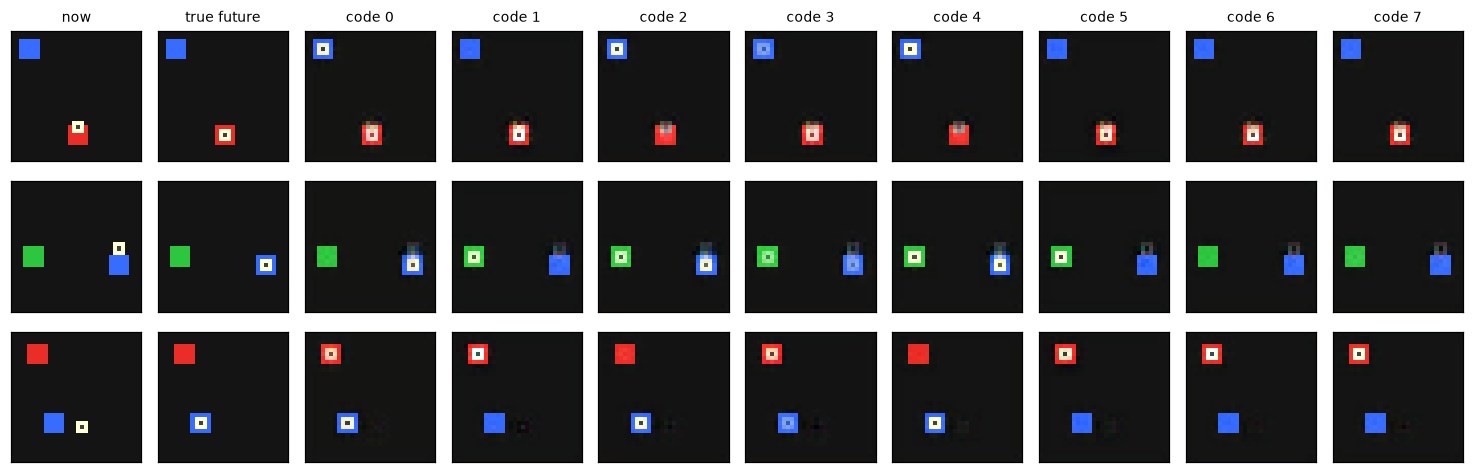

In [15]:
x, f, extras = sampler(1000, np.random.default_rng(5))
with torch.no_grad():
    ze = lam.encode(x, f); _, idx, zq = lam.quantize(ze)
    err_code = ((lam.decode(x, zq) - f) ** 2).mean().item()
    err_shuffled = ((lam.decode(x, zq[torch.randperm(len(zq))]) - f) ** 2).mean().item()
    err_nochange = ((x - f) ** 2).mean().item()
plots.bar_compare({"no change": err_nochange, "wrong (shuffled) code": err_shuffled, "its own code": err_code}, "mean squared error of the future frame", "does the code carry what happened?", fmt="{:.4f}", colors=["#9e9e9e", "#f58518", "#4c78a8"])
print("codes in use on held-out pairs:", np.bincount(idx.numpy(), minlength=8))
plots.plot_latent_counterfactuals(lam, x[:3], f[:3])

**Reading the pictures.** Row 1-3, left to right: the current frame, the true future, then the future *imagined* by the decoder for each of the 8 codes. Different codes move the robot dot to **different places**
(toward different objects or by different amounts), and the decoder with the code *chosen by the encoder* reconstructs the true future an order of magnitude better than with a wrong code. So the latent is a genuine
"what happened" variable obtained **without any action label**.

One honest caveat that the original paper's picture (Fig. 4: the same latent = "move the right arm left" across 8 embodiments) hides: in our world the best code for a pair depends on *where the objects are*, so a code is a
**scene-relative** intent ("head for the object on that side"), not an absolute direction. A linear probe from the latent to the robot's absolute displacement therefore finds almost nothing (R² ≈ 0), although the codes
are clearly informative. Whether such a label is a good *action target* is an empirical question: Step 8 measures it.

## Step 8: Cross-embodiment pre-training, then post-training a new robot

GR00T N1 is pre-trained on a pyramid of data and then **post-trained on one embodiment with little data**. We reproduce the shape of that pipeline: a *target* embodiment (`gripper3d`) with only 50 or 100
demonstrations (red and green targets only), starting from four different initialisations of the shared DiT:

* **scratch**: only the VLM is pre-trained (VQA); the DiT and all embodiment MLPs are random;
* **robot**: pre-trained on abundant demonstrations of the *other* bodies (`point2d` and `joint2d`; the gripper body and its MLPs have never been trained);
* **video only**: pre-trained on action-less video (all three colours) labelled by the latent-action model;
* **robot + video**: both, mixed 80 % / 20 %.

Post-training uses the target's own fresh state / action MLPs and updates everything. We evaluate on red/green targets and on **blue**, a colour that *no robot demonstration* ever had as a target (only the video did).

In [16]:
robot_demos = make_reach_demos(gen, 3000, np.random.default_rng(0), RG)
robot_srcs = [EmbodiedSource(world, robot_demos, EMBODIMENTS["point2d"]), EmbodiedSource(world, robot_demos, EMBODIMENTS["joint2d"])]
def pretrain(srcs, weights, steps=3000):
    torch.manual_seed(0)
    m = GR00TPolicy(vlm, GR00TConfig.n1())
    h = PiTrainer(m, EmbodiedMixture(srcs, weights, latent_fn=lam.latent), batch_size=64, lr=2e-3, grad_clip=10.0).fit(steps)
    print(f"  pre-trained in {h.seconds:.0f} s", flush=True)
    return m
print("robot-only:"); pre_robot = pretrain(robot_srcs, [0.5, 0.5])
print("video-only (latent actions):"); pre_video = pretrain([video_src], [1.0])
print("robot + video:"); pre_both = pretrain(robot_srcs + [video_src], [0.4, 0.4, 0.2])
inits = {"scratch": None, "robot": pre_robot, "video only": pre_video, "robot + video": pre_both}
sc_rg = make_embodied_scenarios(gen, "gripper3d", 96, 123, colors=RG)
sc_blue = make_embodied_scenarios(gen, "gripper3d", 96, 123, target="blue")

robot-only:


  pre-trained in 125 s


video-only (latent actions):


  pre-trained in 154 s


robot + video:


  pre-trained in 127 s


 50 target demos | scratch        | red/green 0.04 | blue (never demonstrated) 0.02


 50 target demos | robot          | red/green 0.26 | blue (never demonstrated) 0.01


 50 target demos | video only     | red/green 0.18 | blue (never demonstrated) 0.03


 50 target demos | robot + video  | red/green 0.57 | blue (never demonstrated) 0.03


100 target demos | scratch        | red/green 0.18 | blue (never demonstrated) 0.03


100 target demos | robot          | red/green 0.88 | blue (never demonstrated) 0.01


100 target demos | video only     | red/green 0.17 | blue (never demonstrated) 0.04


100 target demos | robot + video  | red/green 0.91 | blue (never demonstrated) 0.03


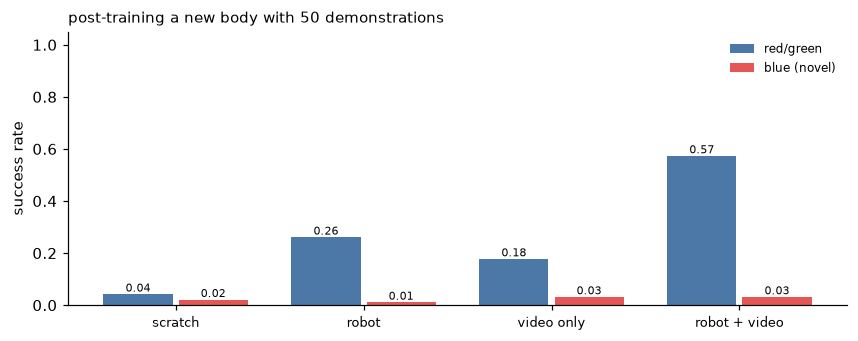

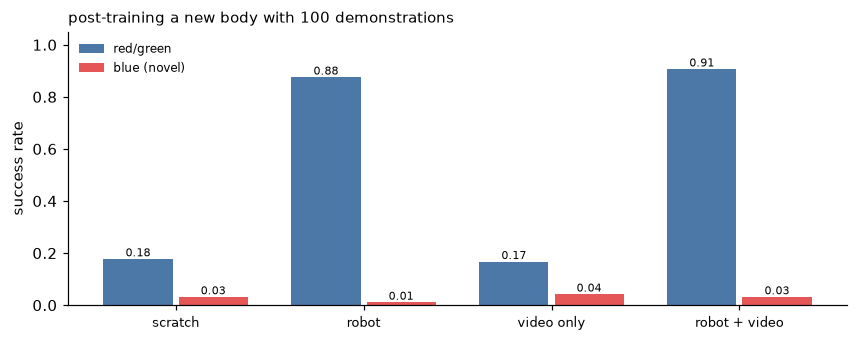

In [17]:
post = {}
for n_demos in (50, 100):
    few = make_reach_demos(gen, n_demos, np.random.default_rng(2), RG)
    for name, init in inits.items():
        torch.manual_seed(0)
        m = GR00TPolicy(vlm, GR00TConfig.n1()) if init is None else copy.deepcopy(init)
        PiTrainer(m, EmbodiedMixture([EmbodiedSource(world, few, EMBODIMENTS["gripper3d"])]), batch_size=64, lr=1e-3, grad_clip=10.0).fit(1500)
        post[(n_demos, name)] = dict(rg=ev.run(lambda b: m.sample_actions(b), sc_rg).success_rate, blue=ev.run(lambda b: m.sample_actions(b), sc_blue).success_rate)
        print(f"{n_demos:3d} target demos | {name:14s} | red/green {post[(n_demos, name)]['rg']:.2f} | blue (never demonstrated) {post[(n_demos, name)]['blue']:.2f}", flush=True)
for n_demos in (50, 100):
    plots.grouped_bars({name: {"red/green": post[(n_demos, name)]["rg"], "blue (novel)": post[(n_demos, name)]["blue"]} for name in inits}, "success rate", f"post-training a new body with {n_demos} demonstrations", colors=["#4c78a8", "#e45756"])

**What to take from this.** A caution first: we executed this section twice with identical seeds and the 50-demonstration cells moved by up to ~25 points between runs (multithreaded CPU arithmetic is not bit-reproducible),
so only the *large* effects below are trustworthy.

* **Pre-training on other robots transfers.** With 100 target demonstrations the scratch model fails (≈ 20 % success) while the model pre-trained on `point2d` + `joint2d` reaches ≈ 80-90 % in both of our runs: the shared DiT and VLM already
  know how to turn "instruction + scene" into motion, and only the thin per-embodiment MLPs of the new body are learned from scratch. With 50 demonstrations everything is noisy (the pre-trained models land between 26 % and 57 %).
  This is the economic argument of N1: spend the compute once, fit each new robot with little data. (Fine-tuning needs a *smaller learning rate* than pre-training, 1e-3 vs 2e-3 here: at 2e-3 the same pre-trained model reached only 59 % with
  100 demonstrations.)
* **Latent-action video, on its own, is not a reliable teacher here.** The video-only model stays near scratch at 100 demonstrations, and adding video to the robot data is indistinguishable from robot data alone (the two orderings
  flipped between our two runs). Our latent actions are *scene-relative* codes from 3000 clips (Step 7), a weak flow-matching target, and we therefore do **not** claim to reproduce the paper's gain from latent-action video; that design needs far
  more and far more varied video than a toy world has.
* **The never-demonstrated colour (blue) stays near zero for every initialisation here**: no robot ever moved toward blue, and the DiT does not extrapolate that mapping. (Step 9 shows what *does* preserve blue.)

## Step 9: From N1 to N1.5

NVIDIA's GR00T N1.5 release notes list four changes. Three are architectural and testable here:

1. **A frozen VLM.** *"The VLM model is frozen during both pretraining and finetuning"* (N1 fine-tuned the vision encoder). Frozen features cannot drift away from the web-pre-trained semantics, which the notes credit for better language
   following and generalisation.
2. **A simplified adapter with LayerNorm** on the visual and text tokens between the VLM and the DiT: *"greatly improved language following and generalization"*.
3. **FLARE** (Future LAtent REpresentation Alignment), loss weight 0.2.
4. New data (DreamGen neural trajectories): not reproducible here.

### FLARE in one picture

M learnable **future tokens** are appended to the DiT's input sequence `[state | noised actions | future tokens]`. At a middle block, the activations at those tokens are passed through an MLP and aligned (cosine similarity) with the
embedding of the **future observation** `x_{t+H}` produced by a frozen encoder:

$$\mathcal{L} = \mathcal{L}_{\text{flow}} + \lambda\,\mathcal{L}_{\text{align}},\qquad \mathcal{L}_{\text{align}} = -\,\mathbb{E}\big[\cos\big(f_\theta(\varphi_t, A^\tau, q_t),\; g(\varphi_{t+H})\big)\big],\quad \lambda = 0.2$$

It needs **no action label**, so it can train on action-less human video; and it makes the policy represent *where things are going* while generating actions. In the paper the target is an "action-aware" compact embedding (a Q-former
of SigLIP-2 features, pre-trained with the flow-matching objective); ours is simpler: the pooled token grid of a frozen copy of the pre-trained vision encoder.

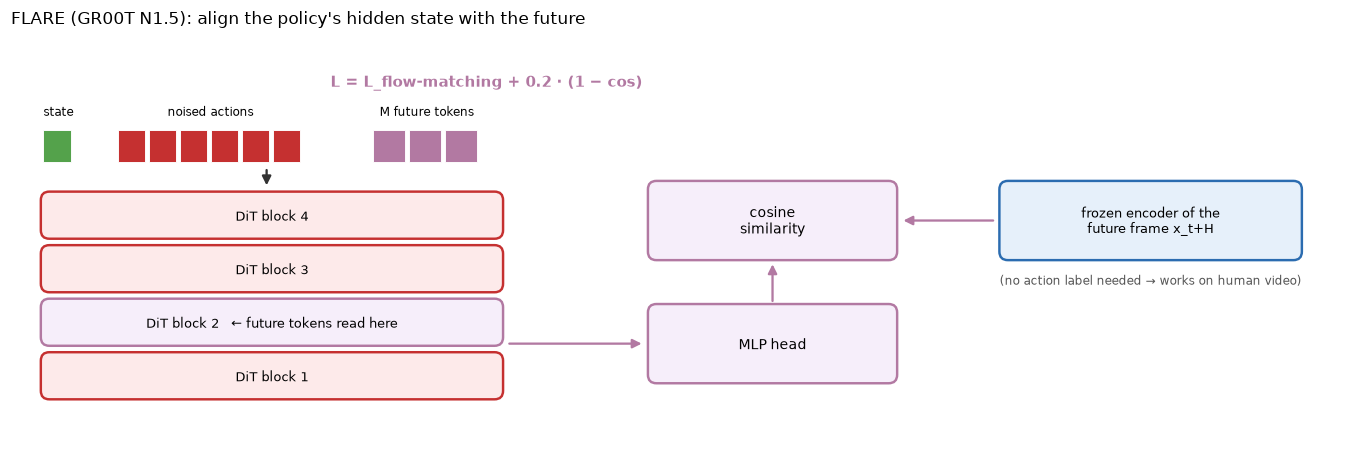

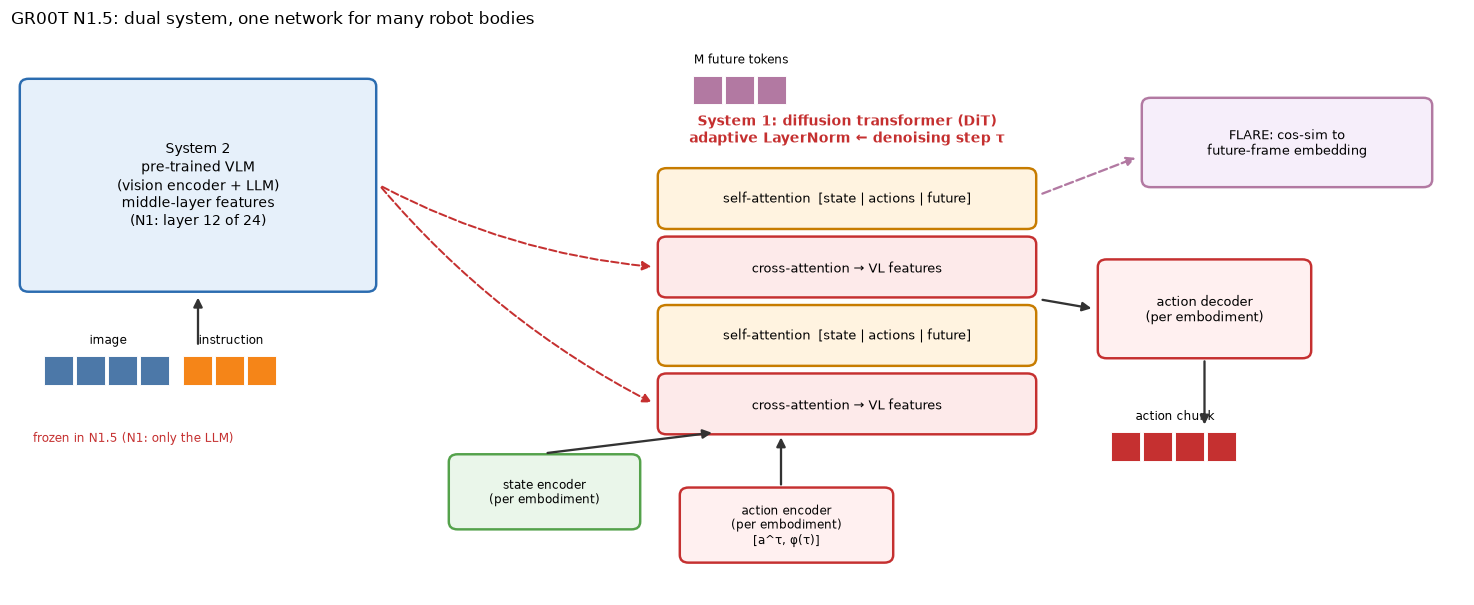

In [18]:
dg.fig_flare()
dg.fig_groot_architecture(flare=True)

In [19]:
n15 = GR00TPolicy(vlm, GR00TConfig.n1_5())
print("N1.5 trainable parameters:", f"{n15.parameter_counts()['trainable']:,}", "(N1:", f"{n1.parameter_counts()['trainable']:,})  →  VLM frozen entirely:", not any(p.requires_grad for p in n15.vlm.parameters()))
print("future tokens:", tuple(n15.future_tokens.shape), "| FLARE target (frozen vision encoder, pooled to 2x2 cells):", tuple(n15.future_targets(batch.future_images).shape))
with torch.no_grad():
    ctx = n15.encode(batch)
    out, fut = n15.velocity(ctx, noisy, torch.full((6,), 0.3), state, emb, return_future=True)
print("future-token activations at DiT block", n15.cfg.flare_layer, ":", tuple(fut.shape), "→ MLP head → cosine against the future-frame embedding")

N1.5 trainable parameters: 269,584 (N1: 286,608)  →  VLM frozen entirely: True
future tokens: (1, 4, 64) | FLARE target (frozen vision encoder, pooled to 2x2 cells): (6, 4, 64)
future-token activations at DiT block 2 : (6, 4, 64) → MLP head → cosine against the future-frame embedding


### An N1 → N1.5 ladder

A single co-training stage on abundant `point2d` demonstrations (red and green) plus **50 `gripper3d` demonstrations** (red and green), 3000 steps, evaluating `gripper3d`. We add one N1.5 ingredient at a time:

| variant | what changes |
|---|---|
| N1 | language frozen, vision encoder trained |
| + frozen VLM | the whole VLM frozen |
| + LayerNorm adapter | LayerNorm on the VLM tokens before the DiT |
| + FLARE (= N1.5) | future tokens, loss weight 0.2 on the robot samples' future frames |
| N1.5 + video | the same, plus action-less **video of blue targets** with *only* the FLARE loss (the paper's human-video co-training) |

N1                           red/green 1.00 | blue 0.03 | trainable 286,608 | flow loss 0.016


+ frozen VLM                 red/green 0.93 | blue 0.49 | trainable 260,880 | flow loss 0.025


+ LayerNorm adapter          red/green 0.82 | blue 0.68 | trainable 261,008 | flow loss 0.023


+ FLARE (N1.5)               red/green 0.85 | blue 0.62 | trainable 269,584 | flow loss 0.025


N1.5 + video (FLARE only)    red/green 0.79 | blue 0.62 | trainable 269,584 | flow loss 0.026


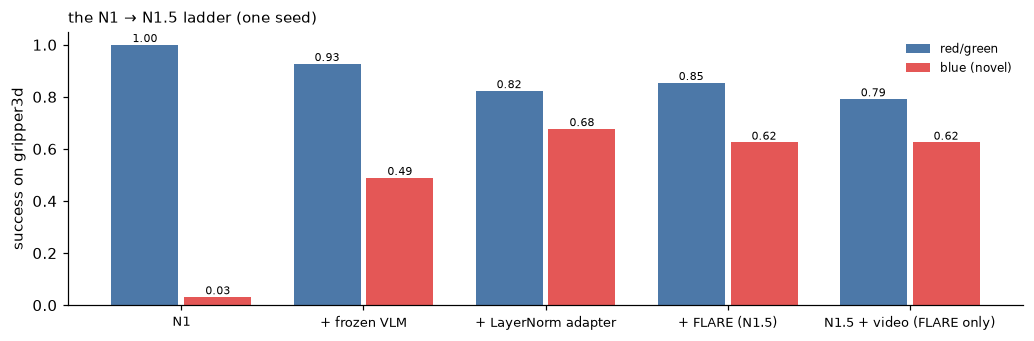

In [20]:
few50 = make_reach_demos(gen, 50, np.random.default_rng(2), RG)
src_robot = EmbodiedSource(world, robot_demos, EMBODIMENTS["point2d"])
src_few = EmbodiedSource(world, few50, EMBODIMENTS["gripper3d"])
src_video = EmbodiedSource(world, video_demos, EMBODIMENTS["lapa"], flow_weight=0.0)      # FLARE only: the flow loss is switched off for these samples
ladder = {
    "N1": (GR00TConfig.n1(), [src_robot, src_few], [0.5, 0.5]),
    "+ frozen VLM": (GR00TConfig.n1(freeze="all"), [src_robot, src_few], [0.5, 0.5]),
    "+ LayerNorm adapter": (GR00TConfig.n1(freeze="all", vl_layernorm=True), [src_robot, src_few], [0.5, 0.5]),
    "+ FLARE (N1.5)": (GR00TConfig.n1_5(), [src_robot, src_few], [0.5, 0.5]),
    "N1.5 + video (FLARE only)": (GR00TConfig.n1_5(), [src_robot, src_few, src_video], [0.4, 0.4, 0.2]),
}
ladder_res = {}
for name, (c, srcs, w) in ladder.items():
    torch.manual_seed(0)
    m = GR00TPolicy(vlm, c)
    h = PiTrainer(m, EmbodiedMixture(srcs, w), batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000)
    ladder_res[name] = dict(rg=ev.run(lambda b: m.sample_actions(b), sc_rg).success_rate, blue=ev.run(lambda b: m.sample_actions(b), sc_blue).success_rate,
                            trainable=m.parameter_counts()["trainable"], flow=float(np.mean(h.series("flow")[-100:])))
    print(f"{name:28s} red/green {ladder_res[name]['rg']:.2f} | blue {ladder_res[name]['blue']:.2f} | trainable {ladder_res[name]['trainable']:,} | flow loss {ladder_res[name]['flow']:.3f}", flush=True)
plots.grouped_bars({k: {"red/green": v["rg"], "blue (novel)": v["blue"]} for k, v in ladder_res.items()}, "success on gripper3d", "the N1 → N1.5 ladder (one seed)", colors=["#4c78a8", "#e45756"])

**Reading the ladder** (single seed, 96 scenes; read gaps below ~10 points as noise):

* **The frozen VLM is the big effect, and it shows up exactly where the N1.5 notes say it should: generalisation.** With the vision encoder *trained* (N1), red/green is near perfect but **blue, which no robot demonstration ever
  targeted, drops to chance (≈5 %)**: fine-tuning the vision encoder on red and green targets erased the pre-trained VLM's grounding of "blue". Freezing the whole VLM keeps blue available to the DiT (≈50-70 %) for a small cost on the
  seen colours (≈1.00 → 0.84-0.94). That is a clean toy version of catastrophic forgetting, and the reason N1.5 freezes the VLM in both pre-training and fine-tuning.
* The **LayerNorm adapter** and **FLARE** rungs are within noise of each other and of the frozen baseline on this task: the N1.5 notes attribute those gains to real-world language following and to learning from *human video*
  at a scale and diversity we cannot generate. FLARE's claimed superpower, co-training on action-less video, did not add measurably over the frozen VLM here (the last row); with only one target object per scene there
  is little "future" to anticipate that the current frame does not already reveal.
* **Honest summary:** we reproduce the *mechanism and motivation* of N1.5 (freeze the VLM to keep its semantics), not the paper's FLARE gains.

## Step 10: Recap and exercises

```
images ─► vision encoder ─┐                           ┌─ N1: language frozen, vision trained │ N1.5: all frozen, + LayerNorm
instruction ─► tokens ────┴─► VLM, layers 1…12 ──────►│  middle-layer features φ_t   (the layers above are never run)
                                                      ▼  cross-attention (every other block)
state q_t ─► state encoder[e] ─┐
noise ε, τ ─► action encoder[e] ┴─► DiT: [state | action tokens | (M future tokens)] ──► adaLN(τ) ──► action decoder[e] ─► chunk
                                                                      │ N1.5: future tokens @ middle block ─► MLP ─► cos(·, embed(x_t+H))  (λ = 0.2)
loss = flow matching on A^τ = τA + (1−τ)ε  (+ 0.2·FLARE)      data: robot teleop · simulation · video generation · human video (latent actions)
```

**What GR00T shows:** a single transformer can be trained across robot bodies if only the thin state / action MLPs are embodiment-specific; pre-training on other robots makes a new one cheap to learn; and video
without actions can be turned into training signal either by *labelling* it (latent actions, N1) or by *aligning to its future* (FLARE, N1.5). **What our toy cannot show:** humanoid whole-body control, the effect of
50,000 GPU-hours, or generated "neural trajectories".

### 🧪 Exercises
1. Add a fourth robot to `open_vlas/embodiments.py` (say a 5-D action space) and check that the routing (Step 2) still works without touching the DiT.
2. Change `GR00TConfig.num_future_tokens` to 16 or `flare_weight` to 0.05 / 1.0 and redo the ladder's last two rows: how sensitive is FLARE (the paper's Table: 0.2 works best)?
3. Replace the FLARE target by the *current* frame's embedding (REPA-style). Does predicting the future matter more than aligning at all?
4. Pre-train the latent-action model on video from `point2d` only and use it to label `gripper3d` video: is the latent shared across bodies, as the paper claims?
5. Use `freeze="none"` (fine-tune the whole VLM) and compare forgetting: ask the pre-trained VLM *where is blue?* before and after post-training (`VLMPretrainer.ask`).